# 🚀 Practice Day 46

**📅 Date:** **2026-10-29**  
**📁 Category:** **Phase 1 · 시각화 기초 (Round 4/5)**

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice core chart types (bar, line, and pie) to compare movie genres and show the seasonal pattern across a year
  (막대·선·파이 그래프 등 기본 차트 유형 연습 — 장르 비교와 연중 계절성 표현)
- Find which movie genre drives the most revenue and when the theater's busiest months are
  (어떤 장르가 매출을 가장 많이 견인하는지, 영화관이 가장 붐비는 달은 언제인지 파악하기)

---
# 📂 Dataset

**Dataset Name:** Lumina Cinemas — Monthly Revenue by Genre (2024) / Lumina Cinemas — 장르별 월간 매출 (2024)

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 2024 monthly ticket sales for a movie theater, covering 6 genres (Action, Comedy, Drama, Animation, Horror, Romance) — 72 rows total (6 genres × 12 months), single table. Revenue is in USD. Action and Animation spike in summer (blockbuster season), Horror spikes sharply in October, and Romance bumps up in February. Clean — no missing values or duplicates.
(영화관의 2024년 1~12월 티켓 판매 데이터로, 6개 장르(Action/Comedy/Drama/Animation/Horror/Romance)별 월간 판매량과 매출을 담고 있습니다(단일 테이블, 72행 = 6장르×12개월). 매출은 USD입니다. Action·Animation은 여름 성수기에, Horror는 10월에 뚜렷하게 급증하고, Romance는 2월에 소폭 상승합니다. 결측치·중복 없이 깨끗합니다.)

## Dataset Preview

In [32]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate monthly ticket sales by genre for a movie theater ---
genres = ['Action', 'Comedy', 'Drama', 'Animation', 'Horror', 'Romance']
avg_price = {'Action': 13, 'Comedy': 11, 'Drama': 11, 'Animation': 10, 'Horror': 12, 'Romance': 11}  # USD
base_tickets = {'Action': 5200, 'Comedy': 3600, 'Drama': 3000, 'Animation': 4800, 'Horror': 2200, 'Romance': 1800}

months = pd.date_range('2024-01-01', periods=12, freq='MS')
# Seasonal index per genre per month (Jan..Dec): summer blockbuster bump for Action/Animation,
# an October spike for Horror, and a February bump for Romance
seasonal = {
    'Action':    [0.85, 0.8, 0.9, 0.95, 1.1, 1.4, 1.5, 1.3, 0.9, 0.85, 0.9, 1.15],
    'Comedy':    [0.9, 0.85, 0.95, 1.0, 1.0, 1.1, 1.1, 1.05, 0.95, 0.9, 0.95, 1.1],
    'Drama':     [1.0, 0.95, 1.0, 1.0, 0.95, 0.9, 0.9, 0.95, 1.0, 1.05, 1.05, 1.15],
    'Animation': [0.8, 0.85, 0.9, 1.0, 1.1, 1.35, 1.45, 1.25, 0.9, 0.85, 0.95, 1.3],
    'Horror':    [0.7, 0.7, 0.75, 0.8, 0.85, 0.9, 0.9, 0.95, 1.1, 2.2, 1.2, 0.8],
    'Romance':   [1.3, 1.5, 1.1, 1.0, 0.95, 0.9, 0.9, 0.9, 0.9, 0.9, 0.95, 1.1],
}

rows = []
for g in genres:
    for i, m in enumerate(months):
        noise = rng.normal(1.0, 0.06)
        tickets = base_tickets[g] * seasonal[g][i] * noise
        tickets = max(1, int(round(tickets)))
        revenue = tickets * avg_price[g]
        rows.append({'month': m, 'genre': g, 'tickets_sold': tickets, 'revenue': revenue})

df = pd.DataFrame(rows).sort_values(['month', 'genre']).reset_index(drop=True)

df.head(10)


,month,genre,tickets_sold,revenue
0,2024-01-01,Action,4501,58513
1,2024-01-01,Animation,3814,38140
2,2024-01-01,Comedy,3253,35783
3,2024-01-01,Drama,2923,32153
4,2024-01-01,Horror,1603,19236
5,2024-01-01,Romance,2104,23144
6,2024-02-01,Action,3900,50700
7,2024-02-01,Animation,3874,38740
8,2024-02-01,Comedy,3267,35937
9,2024-02-01,Drama,2790,30690


## Dataset Information

In [33]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   month         72 non-null     datetime64[us]
 1   genre         72 non-null     str           
 2   tickets_sold  72 non-null     int64         
 3   revenue       72 non-null     int64         
dtypes: datetime64[us](1), int64(2), str(1)
memory usage: 2.4 KB

Shape: (72, 4)


,month,genre,tickets_sold,revenue
count,72,72,72.000000,72.000000
unique,NaN,6,NaN,NaN
top,NaN,Action,NaN,NaN
freq,NaN,12,NaN,NaN
mean,2024-06-16 08:00:00,NaN,3521.500000,40049.500000
min,2024-01-01 00:00:00,NaN,1546.000000,17325.000000
25%,2024-03-24 06:00:00,NaN,2007.250000,23264.000000
50%,2024-06-16 00:00:00,NaN,3266.500000,35931.500000
75%,2024-09-08 12:00:00,NaN,4387.750000,50077.500000
max,2024-12-01 00:00:00,NaN,7860.000000,102180.000000


---
# ❓ Business Questions

1. **(Analysis)** Which genre generates the most total revenue, and which the least?
   (가장 매출이 높은/낮은 장르는?)
2. **(Analysis)** How does total monthly ticket volume (all genres combined) change across the year?
   (전체 티켓 판매량은 월별로 어떻게 변화하는가?)
3. **(Analysis)** What percentage of total annual revenue does each genre contribute?
   (장르별 연간 매출 비중은 각각 몇 %인가?)
4. **(Visualization)** Compare total revenue across all 6 genres.
   (6개 장르의 총매출을 비교하면?)
5. **(Visualization)** Show how total monthly ticket sales move across the year.
   (연중 월별 총 판매량은 어떻게 움직이는가?)

---
# 🔍 Data Cleaning Check


In [34]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
month           0
genre           0
tickets_sold    0
revenue         0
dtype: int64

Duplicate rows: 0

Dtypes
month           datetime64[us]
genre                      str
tickets_sold             int64
revenue                  int64
dtype: object

Column names
['month', 'genre', 'tickets_sold', 'revenue']

Text columns — unique counts
genre    6
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** Which genre generates the most total revenue, and which the least? (가장 매출이 높은/낮은 장르는?)

**Result:** Action has the highest revenue at **$842,647**. Romance has the lowest at **$241,791**. The gap is **$600,856**.  
(매출 1위는 Action $842,647, 맨 아래는 Romance $241,791. 차이는 $600,856)

**Insight:** Animation is next at **$613,590**, which is **$229,057** below Action. Comedy is **$471,724**, Drama **$398,728**, and Horror **$315,084**.  
(다음은 Animation $613,590으로 Action보다 $229,057 적음. Comedy $471,724, Drama $398,728, Horror $315,084)

In [35]:
# Question 1: total revenue by genre (highest / lowest)
revenue_by_genre = df.groupby('genre')['revenue'].sum().sort_values(ascending=False)

revenue_by_genre

genre
Action       842647
Animation    613590
Comedy       471724
Drama        398728
Horror       315084
Romance      241791
Name: revenue, dtype: int64

## Question 2

**Question:** How does total monthly ticket volume (all genres combined) change across the year? (월별 총 판매량 변화는?)

**Result:** Tickets bottom in February at **18,023** and peak in July at **25,268**. December is **23,897**.  
(판매량은 2월 18,023장이 가장 적고 7월 25,268장이 가장 많음. 12월은 23,897장)

**Insight:** July is **7,245** tickets above February. The largest monthly rise is December, **+15.2%**. The largest drop is September, **-15.1%**.  
(7월이 2월보다 7,245장 많음. 전월 대비 가장 큰 상승은 12월 +15.2%, 가장 큰 하락은 9월 -15.1%)

In [36]:
# Question 2: total monthly ticket volume (all genres combined) across the year
monthly_sales = df.groupby('month')['tickets_sold'].sum().reset_index()
monthly_sales['previous'] = monthly_sales['tickets_sold'].shift(1)
monthly_sales['change'] = monthly_sales['tickets_sold'] - monthly_sales['previous']
monthly_sales['pct_change'] = monthly_sales['change'] / monthly_sales['previous'] * 100

monthly_sales

,month,tickets_sold,previous,change,pct_change
0,2024-01-01,18198,NaN,NaN,NaN
1,2024-02-01,18023,18198.0,-175.0,-0.961644
2,2024-03-01,19287,18023.0,1264.0,7.013261
3,2024-04-01,20376,19287.0,1089.0,5.646290
4,2024-05-01,20656,20376.0,280.0,1.374166
5,2024-06-01,23543,20656.0,2887.0,13.976569
6,2024-07-01,25268,23543.0,1725.0,7.327019
7,2024-08-01,22851,25268.0,-2417.0,-9.565458
8,2024-09-01,19398,22851.0,-3453.0,-15.110936
9,2024-10-01,21307,19398.0,1909.0,9.841221


## Question 3

**Question:** What percentage of total annual revenue does each genre contribute? (장르별 연간 매출 비중은?)

**Result:** Action is **29.2%**, Animation **21.3%**, Comedy **16.4%**, Drama **13.8%**, Horror **10.9%**, and Romance **8.4%**.  
(Action 29.2%, Animation 21.3%, Comedy 16.4%, Drama 13.8%, Horror 10.9%, Romance 8.4%)

**Insight:** Action is **20.8** percentage points above Romance and **7.9** above Animation. Action and Animation together are **50.5%**.  
(Action이 Romance보다 20.8%p, Animation보다 7.9%p 높음. Action과 Animation을 더하면 50.5%)

In [37]:
# Question 3: each genre's % share of total annual revenue
revenue = df.groupby('genre')['revenue'].sum()

revenue / revenue.sum() * 100

genre
Action       29.222414
Animation    21.278876
Comedy       16.359061
Drama        13.827611
Horror       10.926895
Romance       8.385144
Name: revenue, dtype: float64

---
# 📈 Visualization

**Chart 1:** Bar chart — total revenue by genre (막대그래프: 장르별 총매출)

*Interpretation:* The bars follow the revenue table: Action **$842,647**, Animation **$613,590**, Comedy **$471,724**, Drama **$398,728**, Horror **$315,084**, Romance **$241,791**.  
(막대 순서는 매출 표와 같음. Action $842,647, Animation $613,590, Comedy $471,724, Drama $398,728, Horror $315,084, Romance $241,791)

---

**Chart 2:** Line chart — total monthly ticket sales trend (선그래프: 월별 총 판매량 추이)

*Interpretation:* The line peaks in July at **25,268** tickets and bottoms in February at **18,023**. It falls to **19,398** in September, then ends December at **23,897**.  
(선은 7월 25,268장이 정점이고 2월 18,023장이 바닥. 9월에 19,398장까지 떨어진 뒤 12월 23,897장으로 끝남)

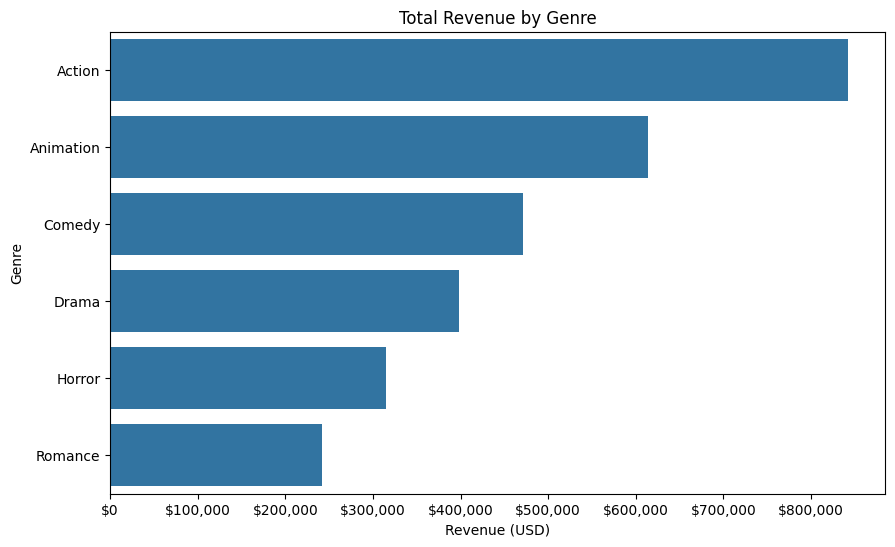

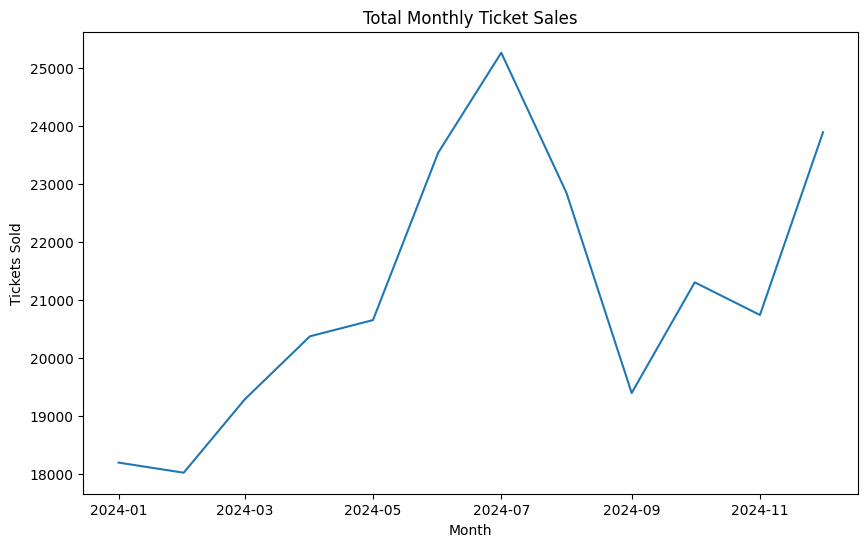

In [38]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: total revenue by genre (bar)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='revenue', y='genre', data=df, ax=ax, estimator=sum, errorbar=None)
ax.xaxis.set_major_formatter('${x:,.0f}')
ax.set_title('Total Revenue by Genre')
ax.set_xlabel('Revenue (USD)')
ax.set_ylabel('Genre')
plt.show()

# Chart 2: total monthly ticket volume across the year (line)
fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(x='month', y='tickets_sold', data=monthly_sales, ax=ax)
ax.set_title('Total Monthly Ticket Sales')
ax.set_xlabel('Month')
ax.set_ylabel('Tickets Sold')
plt.show()



---
# 💼 Business Insights
*What did I discover?*

- Action leads annual revenue at **$842,647**, **29.2%** of the total. Romance is last at **$241,791**, **8.4%**.  
  (연간 매출 1위는 Action $842,647, 전체의 29.2%. Romance는 $241,791, 8.4%로 맨 아래)
- July is the busiest month at **25,268** tickets. February is the quietest at **18,023**.  
  (가장 바쁜 달은 7월 25,268장. 가장 한가한 달은 2월 18,023장)
- September is the sharpest drop, **-15.1%**, and December is the sharpest rise, **+15.2%**.  
  (가장 큰 하락은 9월 -15.1%, 가장 큰 상승은 12월 +15.2%)  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Plan programming around Action. It brings **$842,647**, **$229,057** more than Animation.  
   (상영 계획은 Action을 중심에 둘 것. $842,647로 Animation보다 $229,057 많음)
2. Staff for the July peak of **25,268** tickets, not the February low of **18,023**.  
   (인력은 2월 18,023장이 아니라 7월 25,268장에 맞출 것)
3. Treat September as the slowdown. Ticket volume falls **15.1%** from August, to **19,398**.  
   (9월을 비수기로 볼 것. 판매량이 8월보다 15.1% 줄어 19,398장)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- Chart 1 labeled the revenue axis as Revenue, with no USD and no thousands separator.  
  (차트 1 매출 축이 Revenue로만 적혀 있고, USD와 천 단위 구분도 없었음)  

---
# ✅ What I Learned
*Today's biggest lesson*

- Total revenue by genre is `groupby('genre')['revenue'].sum()`, then sorted descending.  
  (장르별 총매출은 `groupby('genre')['revenue'].sum()` 뒤에 내림차순 정렬)
- Monthly ticket volume has to sum all six genres in each month. The change from the previous month is `shift(1)`.  
  (월별 판매량은 그달의 여섯 장르를 더해야 함. 전월 대비는 `shift(1)`)
- A genre share is that genre's revenue divided by the sum of every genre's revenue. A revenue axis needs USD.  
  (장르 비중은 그 장르 매출을 전체 장르 매출 합으로 나눈 것. 매출 축에는 USD가 필요함)  

---
# 🧠 Reflection

**What was difficult?**  
Reading the year as one ticket total per month, not as six genre rows.  
(한 달을 장르 여섯 행이 아니라 티켓 합계 하나로 읽는 것)

**Why?**  
Each month has six rows, so a mean would not be the theater's monthly volume.  
(매달 행이 여섯 개라서 평균은 영화관 월간 판매량이 아님)

**How did I solve it?**  
Summed `tickets_sold` by month, then used `shift(1)` for the change. Genre shares used the same sum divided by the total.  
(`tickets_sold`를 월별로 더하고, 변화는 `shift(1)`로 구함. 장르 비중도 같은 합을 전체로 나눔)

**What would I do differently next time?**  
Put USD on the revenue axis before reading the bar lengths.  
(막대 길이를 읽기 전에 매출 축에 USD를 붙이기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★★☆☆  
The genre totals, the July peak of **25,268**, and the **29.2%** Action share are clear. A revenue axis still needs a dollar format.  
(장르 합계, 7월 정점 25,268장, Action 비중 29.2%는 이해함. 매출 축은 달러 형식이 필요함)

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★☆☆☆☆☆☆  
The sums were direct. The hard part was combining six genres into one monthly total.  
(합계는 바로 보였음. 어려운 부분은 여섯 장르를 월별 합계 하나로 만드는 것이었음)


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 47 — groupby and pivot (Round 4/5)  
  (지점과 금융상품 유형으로 groupby·pivot)  